<a href="https://colab.research.google.com/github/meetmaniar/INSE-6450/blob/main/Milestone4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Simulated Drift
import os
import time
import tracemalloc
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score, accuracy_score, f1_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
# 1. Load & sort chronologically (exact Milestone 2 pipeline)
GITHUB_CSV_URL = "https://raw.githubusercontent.com/meetmaniar/INSE-6450/main/Occupancy_Estimation.csv"
df = pd.read_csv(GITHUB_CSV_URL)

In [3]:
df['Datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'])
df = df.sort_values('Datetime').reset_index(drop=True)

df['T_mean'] = df[['S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp']].mean(axis=1)
df['L_mean'] = df[['S1_Light', 'S2_Light', 'S3_Light', 'S4_Light']].mean(axis=1)
df['S_mean'] = df[['S1_Sound', 'S2_Sound', 'S3_Sound', 'S4_Sound']].mean(axis=1)

raw_sensor_cols = [
    'S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp',
    'S1_Light', 'S2_Light', 'S3_Light', 'S4_Light',
    'S1_Sound', 'S2_Sound', 'S3_Sound', 'S4_Sound'
]
df = df.drop(columns=raw_sensor_cols)

In [4]:
# 2. Exact 120-block stratified split (random_state=1)
n_blocks = 120
df['block_id'] = pd.qcut(df.index, q=n_blocks, labels=False)

block_summary = df.groupby('block_id')['Room_Occupancy_Count'].agg(max_occupancy='max').reset_index()

train_blocks, test_val_blocks = train_test_split(
    block_summary['block_id'], test_size=0.40, random_state=1, stratify=block_summary['max_occupancy']
)
test_val_strat = block_summary.loc[block_summary['block_id'].isin(test_val_blocks), 'max_occupancy']
val_blocks, test_blocks = train_test_split(
    test_val_blocks, test_size=0.75, random_state=1, stratify=test_val_strat
)

drop_cols = ['Date', 'Time', 'Datetime', 'Room_Occupancy_Count', 'block_id']
FEATURES = [c for c in df.columns if c not in drop_cols]
TARGET = 'Room_Occupancy_Count'

train_df = df[df['block_id'].isin(train_blocks)].copy().reset_index(drop=True)
val_df   = df[df['block_id'].isin(val_blocks)].copy().reset_index(drop=True)
test_df  = df[df['block_id'].isin(test_blocks)].copy().reset_index(drop=True)

In [5]:
# 3. Training, Evaluation & Drift (PSI) Helpers
XGB_PARAMS = dict(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    objective="count:poisson",
    eval_metric="mae",
    early_stopping_rounds=30,
    random_state=42,
)

def train_model(tr, va, version="v1_0_0"):
    weights = np.where(tr[TARGET].isin([2, 3]), 4.0, 1.0)
    model = XGBRegressor(**XGB_PARAMS)

    tracemalloc.start()
    t0 = time.perf_counter()
    model.fit(
        tr[FEATURES], tr[TARGET],
        sample_weight=weights,
        eval_set=[(tr[FEATURES], tr[TARGET]), (va[FEATURES], va[TARGET])],
        verbose=False
    )
    train_s = time.perf_counter() - t0
    _, peak_mem = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    path = f"/tmp/{version}.json"
    model.save_model(path)
    size_kb = os.path.getsize(path) / 1024.0

    sample = va[FEATURES].iloc[[0]]
    latencies = []
    for _ in range(200):
        ts = time.perf_counter()
        _ = model.predict(sample)
        latencies.append((time.perf_counter() - ts) * 1000.0)

    eff = {
        "Update_Time_s": round(train_s, 3),
        "Peak_RAM_MB": round(peak_mem / (1024**2), 2),
        "Size_KB": round(size_kb, 1),
        "Latency_p50_ms": round(float(np.percentile(latencies, 50)), 3)
    }
    return model, eff

def evaluate(model, df_eval):
    preds = np.clip(model.predict(df_eval[FEATURES]), 0, 3)
    y = df_eval[TARGET]
    return {
        "MAE": round(mean_absolute_error(y, preds), 4),
        "RMSE": round(mean_squared_error(y, preds) ** 0.5, 4),
        "R2": round(r2_score(y, preds), 4)
    }

def compute_psi(ref_df, new_df):
    psis = []
    for col in ['T_mean', 'L_mean', 'S_mean', 'S5_CO2', 'S5_CO2_Slope']:
        bins = np.unique(np.quantile(ref_df[col], np.linspace(0, 1, 11)))
        if len(bins) < 3:
            continue
        bins[0], bins[-1] = -np.inf, np.inf
        ref_p = np.clip(np.histogram(ref_df[col], bins=bins)[0] / len(ref_df), 1e-4, None)
        new_p = np.clip(np.histogram(new_df[col], bins=bins)[0] / len(new_df), 1e-4, None)
        psis.append(np.sum((new_p - ref_p) * np.log(new_p / ref_p)))
    return round(float(np.mean(psis)), 3)

# Verify exact Milestone 2 Baseline
cl_model, init_eff = train_model(train_df, val_df, "v1_0_0")
print("Baseline v1.0.0 Test Metrics:", evaluate(cl_model, test_df))
print("Baseline v1.0.0 Efficiency:", init_eff)

Baseline v1.0.0 Test Metrics: {'MAE': 0.1039, 'RMSE': 0.1809, 'R2': 0.9574}
Baseline v1.0.0 Efficiency: {'Update_Time_s': 0.306, 'Peak_RAM_MB': 0.88, 'Size_KB': 261.0, 'Latency_p50_ms': 0.866}


In [6]:
# 1. Split held-out test blocks evenly by peak occupancy into Adaptation (50%) & Evaluation (50%)
test_peaks = test_df.groupby('block_id')[TARGET].max().sort_values()
adapt_b = test_peaks.index[::2]
eval_b  = test_peaks.index[1::2]

base_adapt_df = test_df[test_df['block_id'].isin(adapt_b)].reset_index(drop=True)
base_eval_df  = test_df[test_df['block_id'].isin(eval_b)].reset_index(drop=True)

In [7]:
# 2. Define 4 sequential operational intervals
intervals = [
    {"name": "T1: Normal Baseline",   "temp": 0.0,  "co2": 0.0,   "light": 0.0,  "pir_drop": 0.00},
    {"name": "T2: Mild Spring Drift", "temp": 0.8,  "co2": 45.0,  "light": 5.0,  "pir_drop": 0.00},
    {"name": "T3: Summer OOD Shift",  "temp": 3.5,  "co2": 260.0, "light": 85.0, "pir_drop": 0.10},
    {"name": "T4: Winter HVAC Shift", "temp": -2.5, "co2": 320.0, "light": 110.0,"pir_drop": 0.15},
]

In [8]:
# now simulating

In [9]:
def apply_drift(df_in, temp, co2, light, pir_drop, seed):
    rng = np.random.default_rng(seed)
    d = df_in.copy()
    d['T_mean'] += temp + rng.normal(0, 0.10, len(d))
    d['S5_CO2'] += co2 + rng.normal(0, 5.0, len(d))
    d['L_mean'] += light + rng.normal(0, 1.0, len(d))
    if pir_drop > 0:
        d.loc[rng.random(len(d)) < pir_drop, 'S6_PIR'] = 0
        d.loc[rng.random(len(d)) < pir_drop, 'S7_PIR'] = 0
    return d

static_model = cl_model  # Frozen Milestone 2 baseline (never updated)
ref_df = train_df.copy() # Reference distribution for PSI monitoring
version_num = 0
results = []

In [10]:
# 3. Continual learning loop
for i, step in enumerate(intervals):
    adapt_data = apply_drift(base_adapt_df, step["temp"], step["co2"], step["light"], step["pir_drop"], seed=42 + i)
    eval_data  = apply_drift(base_eval_df,  step["temp"], step["co2"], step["light"], step["pir_drop"], seed=142 + i)

    psi = compute_psi(ref_df, eval_data)
    static_metrics = evaluate(static_model, eval_data)
    pre_metrics    = evaluate(cl_model, eval_data)

    # Trigger update if PSI >= 0.25 or MAE > 0.20 (Milestone 2 SLO)
    triggered = (psi >= 0.25) or (pre_metrics["MAE"] > 0.20)

    if triggered:
        version_num += 1
        ver_tag = f"v1_{version_num}_0"

        # Balanced block split without stratify crash
        adapt_peaks = adapt_data.groupby('block_id')[TARGET].max().sort_values()
        new_va_b = adapt_peaks.index[::4]
        new_tr_b = adapt_peaks.index.difference(new_va_b)
        new_tr = adapt_data[adapt_data['block_id'].isin(new_tr_b)]
        new_va = adapt_data[adapt_data['block_id'].isin(new_va_b)]

       # Retain a balanced subset of original archive (all classes 0-3) + newly observed blocks
        hist_keep = train_df.sample(n=1500, random_state=42)
        buffer_train = pd.concat([new_tr, hist_keep], ignore_index=True)
        buffer_val   = pd.concat([new_va, val_df.sample(n=300, random_state=42)], ignore_index=True)

        cl_model, eff = train_model(buffer_train, buffer_val, version=ver_tag)
        post_metrics = evaluate(cl_model, eval_data)
        ref_df = adapt_data.copy()
    else:
        post_metrics = pre_metrics.copy()
        eff = {"Update_Time_s": 0.0, "Peak_RAM_MB": 0.0, "Size_KB": init_eff["Size_KB"], "Latency_p50_ms": init_eff["Latency_p50_ms"]}

    results.append({
        "Interval": step["name"],
        "PSI": psi,
        "Updated": triggered,
        "Static_MAE": static_metrics["MAE"],
        "Pre_MAE": pre_metrics["MAE"],
        "Post_MAE": post_metrics["MAE"],
        "Static_RMSE": static_metrics["RMSE"],
        "Post_RMSE": post_metrics["RMSE"],
        "Static_R2": static_metrics["R2"],
        "Pre_R2": pre_metrics["R2"],
        "Post_R2": post_metrics["R2"],
        **eff
    })

res_df = pd.DataFrame(results)
display(res_df)

,Interval,PSI,Updated,Static_MAE,Pre_MAE,Post_MAE,Static_RMSE,Post_RMSE,Static_R2,Pre_R2,Post_R2,Update_Time_s,Peak_RAM_MB,Size_KB,Latency_p50_ms
0,T1: Normal Baseline,0.174,False,0.1153,0.1153,0.1153,0.1862,0.1862,0.9630,0.9630,0.9630,0.000,0.00,261.0,0.866
1,T2: Mild Spring Drift,2.514,True,0.1695,0.1695,0.1475,0.2372,0.2698,0.9400,0.9400,0.9223,0.245,0.42,246.5,0.822
2,T3: Summer OOD Shift,4.392,True,1.4714,1.4822,0.2015,1.5593,0.3532,-1.5948,-1.5994,0.8669,0.228,0.41,306.2,0.819
3,T4: Winter HVAC Shift,4.515,True,1.5484,0.2664,0.2135,1.6380,0.4444,-1.8636,0.7249,0.7892,0.231,0.41,295.1,0.835


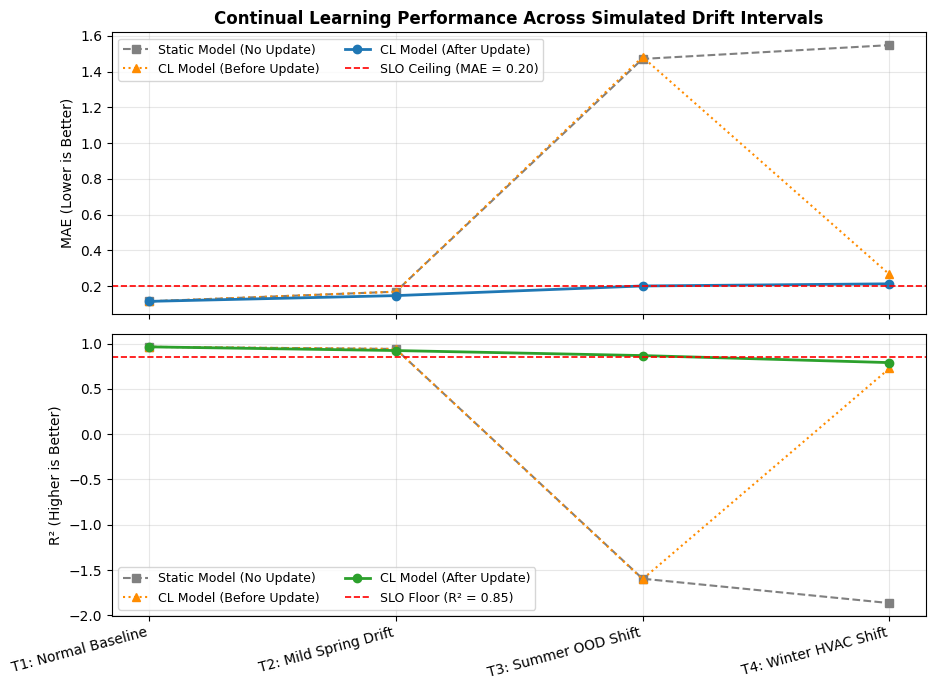

In [11]:
# 4. Plot trajectories across intervals
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9.5, 7.0), sharex=True)
x = np.arange(len(res_df))

# Top plot: MAE Comparison
ax1.plot(x, res_df["Static_MAE"], "s--", color="gray", label="Static Model (No Update)")
ax1.plot(x, res_df["Pre_MAE"], "^:", color="darkorange", label="CL Model (Before Update)")
ax1.plot(x, res_df["Post_MAE"], "o-", color="tab:blue", linewidth=2, label="CL Model (After Update)")
ax1.axhline(0.20, color="red", linestyle="--", linewidth=1.2, label="SLO Ceiling (MAE = 0.20)")
ax1.set_ylabel("MAE (Lower is Better)")
ax1.set_title("Continual Learning Performance Across Simulated Drift Intervals", fontsize=12, fontweight="bold")
ax1.legend(loc="upper left", ncol=2, frameon=True, fontsize=9)
ax1.grid(True, alpha=0.3)

# Bottom plot: R2 Comparison
ax2.plot(x, res_df["Static_R2"], "s--", color="gray", label="Static Model (No Update)")
ax2.plot(x, res_df["Pre_R2"], "^:", color="darkorange", label="CL Model (Before Update)")
ax2.plot(x, res_df["Post_R2"], "o-", color="tab:green", linewidth=2, label="CL Model (After Update)")
ax2.axhline(0.85, color="red", linestyle="--", linewidth=1.2, label="SLO Floor (R² = 0.85)")
ax2.set_ylabel("R² (Higher is Better)")
ax2.set_xticks(x)
ax2.set_xticklabels(res_df["Interval"], rotation=15, ha="right")
ax2.legend(loc="lower left", ncol=2, frameon=True, fontsize=9)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("m4_continual_learning_results.png", dpi=300, bbox_inches="tight")
plt.show()

In [12]:
# hitl an active learning

In [13]:
import time
import tracemalloc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [14]:
# 1. Load & prepare dataset (exact Milestone 2 pipeline)
GITHUB_CSV_URL = "https://raw.githubusercontent.com/meetmaniar/INSE-6450/main/Occupancy_Estimation.csv"
df = pd.read_csv(GITHUB_CSV_URL)
df['Datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'])
df = df.sort_values('Datetime').reset_index(drop=True)

df['T_mean'] = df[['S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp']].mean(axis=1)
df['L_mean'] = df[['S1_Light', 'S2_Light', 'S3_Light', 'S4_Light']].mean(axis=1)
df['S_mean'] = df[['S1_Sound', 'S2_Sound', 'S3_Sound', 'S4_Sound']].mean(axis=1)

raw_sensor_cols = [
    'S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp',
    'S1_Light', 'S2_Light', 'S3_Light', 'S4_Light',
    'S1_Sound', 'S2_Sound', 'S3_Sound', 'S4_Sound'
]
df = df.drop(columns=raw_sensor_cols)

df['block_id'] = pd.qcut(df.index, q=120, labels=False)
block_summary = df.groupby('block_id')['Room_Occupancy_Count'].agg(max_occupancy='max').reset_index()

train_blocks, test_val_blocks = train_test_split(
    block_summary['block_id'], test_size=0.40, random_state=1, stratify=block_summary['max_occupancy']
)
test_val_strat = block_summary.loc[block_summary['block_id'].isin(test_val_blocks), 'max_occupancy']
val_blocks, test_blocks = train_test_split(
    test_val_blocks, test_size=0.75, random_state=1, stratify=test_val_strat
)

FEATURES = ['S5_CO2', 'S5_CO2_Slope', 'S6_PIR', 'S7_PIR', 'T_mean', 'L_mean', 'S_mean']
TARGET = 'Room_Occupancy_Count'

train_df = df[df['block_id'].isin(train_blocks)].reset_index(drop=True)
val_df   = df[df['block_id'].isin(val_blocks)].reset_index(drop=True)
test_df  = df[df['block_id'].isin(test_blocks)].reset_index(drop=True)

In [15]:
# 2. Create Summer OOD Pool (18 blocks) & Held-Out OOD Evaluation Set (18 blocks)
test_peaks = test_df.groupby('block_id')[TARGET].max().sort_values()
pool_b = test_peaks.index[::2]
eval_b = test_peaks.index[1::2]

def apply_summer_drift(df_in, seed):
    rng = np.random.default_rng(seed)
    d = df_in.copy()
    d['T_mean'] += 3.5 + rng.normal(0, 0.10, len(d))
    d['S5_CO2'] += 260.0 + rng.normal(0, 5.0, len(d))
    d['L_mean'] += 85.0 + rng.normal(0, 1.0, len(d))
    d.loc[rng.random(len(d)) < 0.10, 'S6_PIR'] = 0
    d.loc[rng.random(len(d)) < 0.10, 'S7_PIR'] = 0
    return d

unlabeled_pool_df = apply_summer_drift(test_df[test_df['block_id'].isin(pool_b)], seed=44)
ood_eval_df       = apply_summer_drift(test_df[test_df['block_id'].isin(eval_b)], seed=144)

# Inject 2 corrupted sensor-glitch blocks into the unlabeled pool to test HITL Gating
glitch_blocks = list(pool_b[:2])
unlabeled_pool_df.loc[unlabeled_pool_df['block_id'].isin(glitch_blocks), 'S5_CO2'] = 5000.0  # Sensor spike fault
unlabeled_pool_df.loc[unlabeled_pool_df['block_id'].isin(glitch_blocks), 'T_mean'] = -10.0   # Sensor drop fault

In [16]:
# 3. Model Training & Evaluation Helpers
XGB_PARAMS = dict(
    n_estimators=500, learning_rate=0.05, max_depth=5,
    objective="count:poisson", eval_metric="mae",
    early_stopping_rounds=30, random_state=42
)

def fit_and_measure(tr, va):
    weights = np.where(tr[TARGET].isin([2, 3]), 4.0, 1.0)
    m = XGBRegressor(**XGB_PARAMS)
    tracemalloc.start()
    t0 = time.perf_counter()
    m.fit(tr[FEATURES], tr[TARGET], sample_weight=weights,
          eval_set=[(tr[FEATURES], tr[TARGET]), (va[FEATURES], va[TARGET])], verbose=False)
    update_s = time.perf_counter() - t0
    _, peak_mem = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    sample = va[FEATURES].iloc[[0]]
    lats = []
    for _ in range(150):
        ts = time.perf_counter()
        _ = m.predict(sample)
        lats.append((time.perf_counter() - ts) * 1000.0)

    return m, {
        "Update_Time_s": round(update_s, 3),
        "Peak_RAM_MB": round(peak_mem / (1024**2), 2),
        "Latency_p50_ms": round(float(np.percentile(lats, 50)), 3)
    }

def eval_ood(m):
    preds = np.clip(m.predict(ood_eval_df[FEATURES]), 0, 3)
    y = ood_eval_df[TARGET]
    return {
        "MAE": round(mean_absolute_error(y, preds), 4),
        "RMSE": round(mean_squared_error(y, preds) ** 0.5, 4),
        "R2": round(r2_score(y, preds), 4)
    }

In [17]:
# 4. Hybrid Active Learning + HITL Gating Query Function
def select_blocks_al_hitl(model, candidate_df, available_blocks, budget=3):
    sub = candidate_df[candidate_df['block_id'].isin(available_blocks)].copy()
    preds = np.clip(model.predict(sub[FEATURES]), 0, 3)

    # Uncertainty: proximity to half-integer boundary + CO2/PIR modality conflict
    boundary_unc = 1.0 - 2.0 * np.abs((preds - np.floor(preds)) - 0.5)
    conflict_unc = ((sub['S5_CO2_Slope'] > 1.5) & (sub['S6_PIR'] == 0) & (sub['S7_PIR'] == 0)).astype(float)
    sub['unc_score'] = 0.7 * boundary_unc + 0.3 * conflict_unc

    block_stats = sub.groupby('block_id').agg(
        mean_unc=('unc_score', 'mean'),
        max_co2=('S5_CO2', 'max'),
        min_temp=('T_mean', 'min'),
        **{f: (f, 'mean') for f in FEATURES}
    ).reset_index()

    # HITL Gate: Operator rejects physical sensor-glitch blocks (CO2 > 2500 ppm or Temp < 5 C)
    valid_blocks = block_stats[(block_stats['max_co2'] <= 2500.0) & (block_stats['min_temp'] >= 5.0)].copy()
    rejected_count = len(block_stats) - len(valid_blocks)

    # Take top uncertain blocks, then enforce diversity via k-Means medoids
    top_pool = valid_blocks.sort_values('mean_unc', ascending=False).head(max(budget * 2, budget))
    if len(top_pool) <= budget:
        return list(top_pool['block_id']), rejected_count

    X_scaled = StandardScaler().fit_transform(top_pool[FEATURES])
    km = KMeans(n_clusters=budget, random_state=42, n_init=10).fit(X_scaled)
    selected = []
    for c in range(budget):
        c_idx = np.where(km.labels_ == c)[0]
        dists = np.linalg.norm(X_scaled[c_idx] - km.cluster_centers_[c], axis=1)
        selected.append(top_pool.iloc[c_idx[np.argmin(dists)]]['block_id'])
    return selected, rejected_count

In [18]:
# 5. Run 3-Cycle Comparison: AL+HITL vs. Random Sampling (No Gate) vs. 100% Upper Bound
base_model, base_eff = fit_and_measure(train_df, val_df)
base_res = eval_ood(base_model)

In [19]:
# Full-labeling upper bound (100% of clean pool labeled at once)
clean_pool_df = unlabeled_pool_df[~unlabeled_pool_df['block_id'].isin(glitch_blocks)]
full_tr = pd.concat([train_df.sample(1500, random_state=42), clean_pool_df], ignore_index=True)
full_va = pd.concat([val_df.sample(300, random_state=42), clean_pool_df.sample(frac=0.25, random_state=42)], ignore_index=True)
full_model, _ = fit_and_measure(full_tr, full_va)
full_res = eval_ood(full_model)

In [20]:
# Cycle 0 (Before any new labels)
al_model, rnd_model = base_model, base_model
al_avail  = list(pool_b)
rnd_avail = list(pool_b)
al_labeled_rows, rnd_labeled_rows = [], []

BUDGET_PER_CYCLE = 3
TOTAL_CLEAN_ROWS = len(clean_pool_df)

cycle_records = [{
    "Cycle": "Cycle 0 (Pre-AL)",
    "Cum_Blocks": 0,
    "Label_Pct": 0.0,
    "HITL_Rejected": 0,
    "AL_MAE": base_res["MAE"], "AL_R2": base_res["R2"],
    "Rnd_MAE": base_res["MAE"], "Rnd_R2": base_res["R2"],
    "Full_MAE": full_res["MAE"], "Full_R2": full_res["R2"],
    **base_eff
}]

rng_rnd = np.random.default_rng(7)
for cyc in range(1, 4):
    # --- A. Active Learning + HITL Gate ---
    chosen_al, rej = select_blocks_al_hitl(al_model, unlabeled_pool_df, al_avail, budget=BUDGET_PER_CYCLE)
    al_avail = [b for b in al_avail if b not in chosen_al]
    al_labeled_rows.append(unlabeled_pool_df[unlabeled_pool_df['block_id'].isin(chosen_al)])
    cur_al_df = pd.concat(al_labeled_rows, ignore_index=True)

    tr_al = pd.concat([train_df.sample(1500, random_state=42), cur_al_df], ignore_index=True)
    va_al = pd.concat([val_df.sample(300, random_state=42), cur_al_df.sample(frac=0.30, random_state=42)], ignore_index=True)
    al_model, eff_al = fit_and_measure(tr_al, va_al)
    m_al = eval_ood(al_model)

    # --- B. Random Sampling Baseline (Without HITL Gate) ---
    chosen_rnd = list(rng_rnd.choice(rnd_avail, size=BUDGET_PER_CYCLE, replace=False))
    rnd_avail = [b for b in rnd_avail if b not in chosen_rnd]
    rnd_labeled_rows.append(unlabeled_pool_df[unlabeled_pool_df['block_id'].isin(chosen_rnd)])
    cur_rnd_df = pd.concat(rnd_labeled_rows, ignore_index=True)

    tr_rnd = pd.concat([train_df.sample(1500, random_state=42), cur_rnd_df], ignore_index=True)
    va_rnd = pd.concat([val_df.sample(300, random_state=42), cur_rnd_df.sample(frac=0.30, random_state=42)], ignore_index=True)
    rnd_model, _ = fit_and_measure(tr_rnd, va_rnd)
    m_rnd = eval_ood(rnd_model)

    cycle_records.append({
        "Cycle": f"Cycle {cyc}",
        "Cum_Blocks": cyc * BUDGET_PER_CYCLE,
        "Label_Pct": round(len(cur_al_df) / TOTAL_CLEAN_ROWS * 100, 1),
        "HITL_Rejected": rej,
        "AL_MAE": m_al["MAE"], "AL_R2": m_al["R2"],
        "Rnd_MAE": m_rnd["MAE"], "Rnd_R2": m_rnd["R2"],
        "Full_MAE": full_res["MAE"], "Full_R2": full_res["R2"],
        **eff_al
    })

al_summary_df = pd.DataFrame(cycle_records)
display(al_summary_df)

,Cycle,Cum_Blocks,Label_Pct,HITL_Rejected,AL_MAE,AL_R2,Rnd_MAE,Rnd_R2,Full_MAE,Full_R2,Update_Time_s,Peak_RAM_MB,Latency_p50_ms
0,Cycle 0 (Pre-AL),0,0.0,0,1.4714,-1.5948,1.4714,-1.5948,0.1493,0.9093,0.261,0.86,0.901
1,Cycle 1,3,18.8,2,0.4310,0.1446,0.3890,0.6859,0.1493,0.9093,0.201,0.30,0.813
2,Cycle 2,6,37.6,2,0.1634,0.9048,0.2927,0.7906,0.1493,0.9093,0.225,0.33,0.819
3,Cycle 3,9,56.4,2,0.2219,0.8579,0.3662,0.6452,0.1493,0.9093,0.216,0.36,0.826


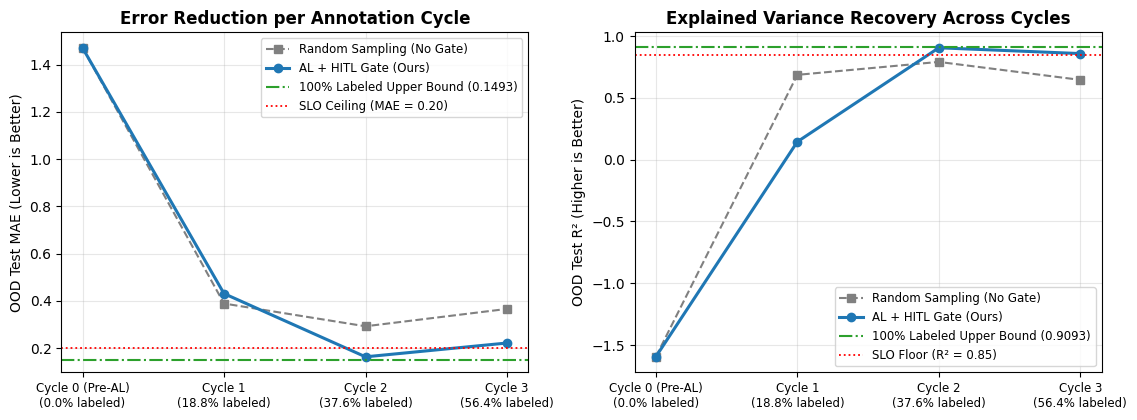

In [21]:
# 6. Plot Learning Efficiency Across Cycles
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.3))
x = np.arange(len(al_summary_df))
labels = [f"{r['Cycle']}\n({r['Label_Pct']}% labeled)" for _, r in al_summary_df.iterrows()]

# Left: MAE
ax1.plot(x, al_summary_df["Rnd_MAE"], "s--", color="gray", label="Random Sampling (No Gate)")
ax1.plot(x, al_summary_df["AL_MAE"], "o-", color="tab:blue", linewidth=2.2, label="AL + HITL Gate (Ours)")
ax1.axhline(full_res["MAE"], color="tab:green", linestyle="-.", label=f"100% Labeled Upper Bound ({full_res['MAE']})")
ax1.axhline(0.20, color="red", linestyle=":", linewidth=1.3, label="SLO Ceiling (MAE = 0.20)")
ax1.set_ylabel("OOD Test MAE (Lower is Better)")
ax1.set_title("Error Reduction per Annotation Cycle", fontweight="bold")
ax1.set_xticks(x)
ax1.set_xticklabels(labels, fontsize=8.5)
ax1.legend(fontsize=8.5)
ax1.grid(True, alpha=0.3)

# Right: R2
ax2.plot(x, al_summary_df["Rnd_R2"], "s--", color="gray", label="Random Sampling (No Gate)")
ax2.plot(x, al_summary_df["AL_R2"], "o-", color="tab:blue", linewidth=2.2, label="AL + HITL Gate (Ours)")
ax2.axhline(full_res["R2"], color="tab:green", linestyle="-.", label=f"100% Labeled Upper Bound ({full_res['R2']})")
ax2.axhline(0.85, color="red", linestyle=":", linewidth=1.3, label="SLO Floor (R² = 0.85)")
ax2.set_ylabel("OOD Test R² (Higher is Better)")
ax2.set_title("Explained Variance Recovery Across Cycles", fontweight="bold")
ax2.set_xticks(x)
ax2.set_xticklabels(labels, fontsize=8.5)
ax2.legend(fontsize=8.5)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("m4_active_learning_cycles.png", dpi=300, bbox_inches="tight")
plt.show()